# 02 — Berth Allocation with FALQON in Ket

**HYPAQ Ports · Eight-qubit simulator experiment · Apache-2.0**

**Execution:** Ket circuits on CPU KBW, not quantum hardware. Default final
counts are reproducible classical draws through Ket's seeded snapshot sampler
from a KBW-computed state. Training and feedback use analytic simulator
expectations, not shot-estimated measurements. No classical simulator fallback
replaces Ket when an error occurs.

Install the pinned dependencies from the repository root before running:

```bash
python -m pip install -r requirements-quantum.txt
```

For Google Colab, clone the repository and install requirements as described in
`notebooks/quantum/README.md`. Run all cells in order. The quantum add-on must
already be merged into the repository.


## 1. Reuse the same model and Hamiltonian convention

In [1]:
from pathlib import Path
import sys
import json
from IPython.display import display, HTML
from html import escape

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src/hypaq_ports/quantum/ket_backend.py").is_file()
             and (p / "data/synthetic/berth_tiny_v1.json").is_file()), None)
if ROOT is None:
    raise RuntimeError("Merge the quantum add-on into hypaq-ports first. See notebooks/quantum/README.md for Colab setup.")
sys.path.insert(0, str(ROOT / "src"))
from hypaq_ports.reference import load_json, solve_berth_exact, build_berth_qubo
from hypaq_ports.quantum import run_qaoa, run_falqon
from hypaq_ports.quantum.ket_backend import environment

instance = load_json(ROOT / "data/synthetic/berth_tiny_v1.json")
config = load_json(ROOT / "results/quantum/berth_experiment.json")
print(json.dumps(environment(), indent=2))
print("Instance:", instance["instance_id"])

def show_rows(rows):
    keys = list(rows[0])
    def cell(value):
        if value is None:
            return "—"
        if isinstance(value, float):
            return f"{value:.6g}"
        return escape(str(value))
    header = "".join(f"<th>{escape(k)}</th>" for k in keys)
    body = "".join("<tr>" + "".join(f"<td>{cell(r.get(k))}</td>" for k in keys) + "</tr>" for r in rows)
    display(HTML(f"<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>"))


{
  "python": "3.12.14",
  "platform": "Linux-6.18.57-x86_64-with-glibc2.39",
  "ket_lang": "0.10.4.2",
  "ket_components": [
    "Ket v0.10.4.2",
    "libket v0.7.1 [rustc 1.97.1 (8bab26f4f 2026-07-14) x86_64-unknown-linux-gnu]",
    "kbw v0.5.1 [GPU, CUDA] [rustc 1.97.1 (8bab26f4f 2026-07-14) x86_64-unknown-linux-gnu]"
  ],
  "numpy": "2.3.5",
  "scipy": "1.17.0"
}
Instance: berth_tiny_v1


## 2. Execute first-order FALQON

Start at beta_0=0 in a uniform superposition. Each layer applies
`exp(-i*dt*H_tilde)` followed by `exp(-i*beta_k*dt*sum X)`.
The next coefficient is `beta_(k+1)=-<i[sum X,H_tilde]>` on the updated state.

A single live KBW state is retained while exact cost and feedback expectations
are queried. Such state inspection is a simulator capability, not a method for
nondestructive expectation measurement on hardware. Finite time steps and
first-order splitting do not guarantee monotonicity or a global optimum.

In [2]:
result = run_falqon(instance, **config["common"], **config["falqon"])
print("Executed:", result["execution_target"])
print("Observed energy increases:", result["energy_increases_observed"])
print("Initial energy:", result["feedback_trace"][0]["full_qubo_energy"])
print("Final energy:", result["feedback_trace"][-1]["full_qubo_energy"])


Executed: KBW CPU state-vector simulator
Observed energy increases: 1
Initial energy: 13.0
Final energy: 2.132430824691145


## 3. Check operational feasibility and sampling

In [3]:
# Check that expectation and readout agree within native simulator precision.
assert abs(result["metrics"]["expected_full_qubo_energy"] -
           result["final_full_energy_from_observable"]) < 0.003
assert sum(result["counts"].values()) == config["common"]["shots"]
print(json.dumps({
    "metrics": {k: v for k, v in result["metrics"].items() if k != "top_sampled_states"},
    "resources": {k: result[k] for k in ["logical_gate_count", "logical_depth",
                  "cost_expectation_queries", "feedback_expectation_queries", "circuit_preparations"]},
    "sampling": result["sampling_description"],
    "elapsed_seconds": result["elapsed_seconds"],
}, indent=2))
show_rows([{k: r[k] for k in ["bits", "count", "probability", "feasible", "waiting_slots", "qubo_energy"]}
           for r in result["metrics"]["top_sampled_states"][:5]])


{
  "metrics": {
    "reference_optimal_waiting_slots": 0,
    "expected_full_qubo_energy": 2.131776992111527,
    "exact_feasible_probability": 0.4089509515263896,
    "exact_optimal_probability": 0.338560552284207,
    "conditional_expected_feasible_waiting_slots": 0.17212430727805828,
    "sampled_feasible_rate": 0.410400390625,
    "sampled_optimal_rate": 0.337890625,
    "best_sampled_feasible_waiting_slots": 0,
    "best_sampled_absolute_gap_slots": 0,
    "best_sampled_feasible_schedule": [
      {
        "vessel": "V1",
        "berth": "B1",
        "slot": 0
      },
      {
        "vessel": "V2",
        "berth": "B2",
        "slot": 1
      }
    ]
  },
  "resources": {
    "logical_gate_count": 4096,
    "logical_depth": 1103,
    "cost_expectation_queries": 65,
    "feedback_expectation_queries": 64,
    "circuit_preparations": 1
  },
  "sampling": "Ket QuantumState.sample on a KBW state snapshot; classical seeded sampling",
  "elapsed_seconds": 2.2432555520008464
}


bits,count,probability,feasible,waiting_slots,qubo_energy
10000001,354,0.0846403,True,0,0
00100001,350,0.08464,True,0,0
00100100,347,0.0846402,True,0,0
10000100,333,0.0846401,True,0,0
01000001,164,0.0351952,True,1,1


## 4. Inspect energy and feedback

Layer zero records the initial energy. The beta computed at layer k is applied at layer k+1. Plot raw observations, including numerical or discretization-related increases.

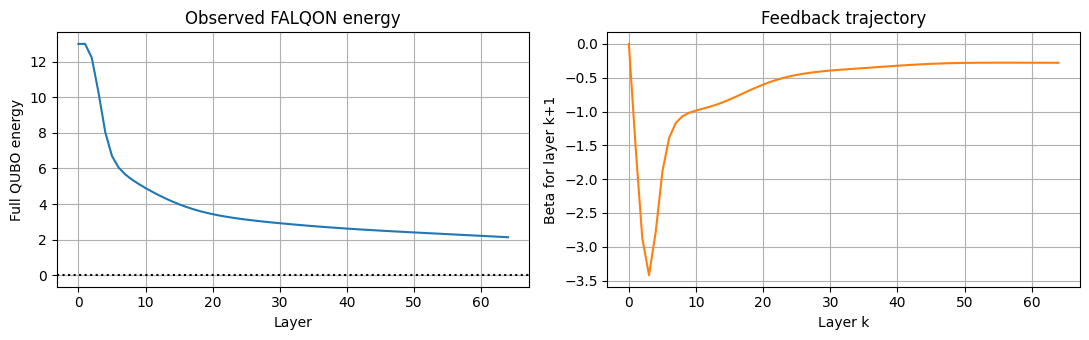

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.grid": True})
trace = result["feedback_trace"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot([r["layer"] for r in trace], [r["full_qubo_energy"] for r in trace])
axes[0].axhline(0, color="black", linestyle=":")
axes[0].set(xlabel="Layer", ylabel="Full QUBO energy", title="Observed FALQON energy")
axes[1].plot([r["layer"] for r in trace], [r["beta_next"] for r in trace], color="tab:orange")
axes[1].set(xlabel="Layer k", ylabel="Beta for layer k+1", title="Feedback trajectory")
plt.tight_layout(); plt.show()


## Explore next

1. Vary dt while recording energy increases, state-norm drift and solution quality.
2. Compare several layer budgets; report feedback-query and gate costs.
3. Use a larger delay or a restricted berth instance after checking classical feasibility.
4. Investigate sampled/noisy feedback separately; the current loop uses exact expectations.

The adapter rejects state-norm drift larger than 1e-4. Very long circuits may
therefore require investigating numerical precision before extending the default
experiment. The current eight-qubit result is an integration experiment, not an
algorithm ranking or an industrial performance claim.